## 1. Environment Initialization
First, we install the `ultralytics` package, which provides the state-of-the-art YOLO architecture. Hardware acceleration (NVIDIA Tesla T4/P100 GPU) must be enabled in the Kaggle session settings to process tensor operations efficiently.

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 23.2 MB/s eta 0:00:00a 0:00:01


## 2. Model Fine-Tuning (Transfer Learning)
We initialize a pre-trained `yolo11n.pt` (Nano) model. The Nano variant is deliberately chosen to ensure ultra-fast inference speed (FPS) for future real-time deployment on edge devices. 

The model is fine-tuned on our custom dataset with the following hyperparameters:
* **epochs=50:** Sufficient iterations for the model to converge without overfitting.
* **imgsz=640:** Standard input resolution for optimal speed-accuracy trade-off.
* **batch=32:** Maximizes the utilization of the 15GB VRAM available on the Kaggle GPU.

In [2]:
from ultralytics import YOLO

# 1. Define Dataset Path
yaml_path = "/kaggle/input/datasets/tranquangduyenk17ct/helmet-detection-1/helmet plate detection 4.v1i.yolov8/data.yaml"

# 2. Initialize a stronger model: YOLO11s (Small) instead of Nano for better real-world accuracy
print("[*] Initializing YOLO11s Model...")
model = YOLO("yolo11s.pt")

# 3. Advanced Training Configuration
print("[*] Starting Professional-Grade Training...")
results = model.train(
    data=yaml_path,
    epochs=150,            # Increased epochs for deep convergence
    patience=25,           # Early stopping: Stops training if no improvement for 25 epochs (Prevents Overfitting)
    imgsz=640,
    batch=32,
    device=0,              # Use GPU
    project="/kaggle/working/SentinelAI",
    name="helmet_model_pro",
    
    # --- ADVANCED DATA AUGMENTATION (Crucial for Real-world Traffic robustness) ---
    mosaic=1.0,            # Combines 4 images into 1 (Forces model to detect smaller objects like far-away plates)
    mixup=0.1,             # Blends two images together
    degrees=10.0,          # Random rotation (+/- 10 degrees) to simulate angled cameras
    translate=0.1,         # Random translation to handle objects at the edges
    scale=0.5,             # Random scaling (zoom in/out)
    hsv_h=0.015,           # Hue augmentation (Simulates different camera sensors)
    hsv_s=0.7,             # Saturation augmentation (Simulates sunny/cloudy days)
    hsv_v=0.4,             # Value/Brightness augmentation (Simulates day/night lighting)
    fliplr=0.5,            # Horizontal flip (Cars moving in opposite directions)
    
    # --- OPTIMIZATION SCHEDULER ---
    optimizer='auto',      # Automatically selects best optimizer (AdamW or SGD)
    cos_lr=True            # Cosine learning rate decay for smoother convergence
)
print("[+] Training Completed Successfully!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[*] Initializing YOLO11s Model...
[*] Starting Professional-Grade Training...
Ultralytics 8.4.26 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/input/datasets/tranquangduyenk17ct/helmet-detection-1/helmet plate detection 4.v1i.yolov8/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing

In [3]:
import os
import glob
from ultralytics import YOLO

# 1. Locate the newly trained best weights
weight_files = glob.glob("/kaggle/working/SentinelAI/helmet_model_pro/weights/best.pt")
best_weight = weight_files[0] if weight_files else None

if not best_weight:
    print("[!] ERROR: Trained weights not found.")
else:
    print(f"[*] Loading Best Model for Evaluation: {best_weight}")
    eval_model = YOLO(best_weight)
    
    # 2. Run validation strictly on the 'test' split
    print("[*] Running Objective Evaluation on Test Dataset...")
    metrics = eval_model.val(
        data=yaml_path, 
        split='test', 
        project="/kaggle/working/SentinelAI", 
        name="evaluation_results"
    )
    
    # 3. Print Professional Academic Metrics
    print("\n" + "="*50)
    print("PROFESSIONAL MODEL EVALUATION REPORT")
    print("="*50)
    print(f"mAP@50 (Mean Average Precision at 50% IoU) : {metrics.box.map50:.4f} (Crucial for general detection)")
    print(f"mAP@50-95 (Strict Average Precision)       : {metrics.box.map:.4f} (Crucial for bounding box tightness)")
    print(f"Precision (Accuracy of positive predictions): {metrics.box.mp:.4f}")
    print(f"Recall (Ability to find all actual objects) : {metrics.box.mr:.4f}")
    print("="*50)

[*] Loading Best Model for Evaluation: /kaggle/working/SentinelAI/helmet_model_pro/weights/best.pt
[*] Running Objective Evaluation on Test Dataset...
Ultralytics 8.4.26 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,961 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 78.1±15.6 MB/s, size: 1007.5 KB)
val: Scanning /kaggle/input/datasets/tranquangduyenk17ct/helmet-detection-1/helmet plate detection 4.v1i.yolov8/test/labels... 168 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 168/168 139.2it/s 1.2s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/tranquangduyenk17ct/helmet-detection-1/helmet plate detection 4.v1i.yolov8/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.1it/s 5.2s0.2s
                   all        168        818      0.987      0.996      0.994      0.812
 

VISUAL ANALYTICS & DIAGNOSTICS
--------------------------------------------------


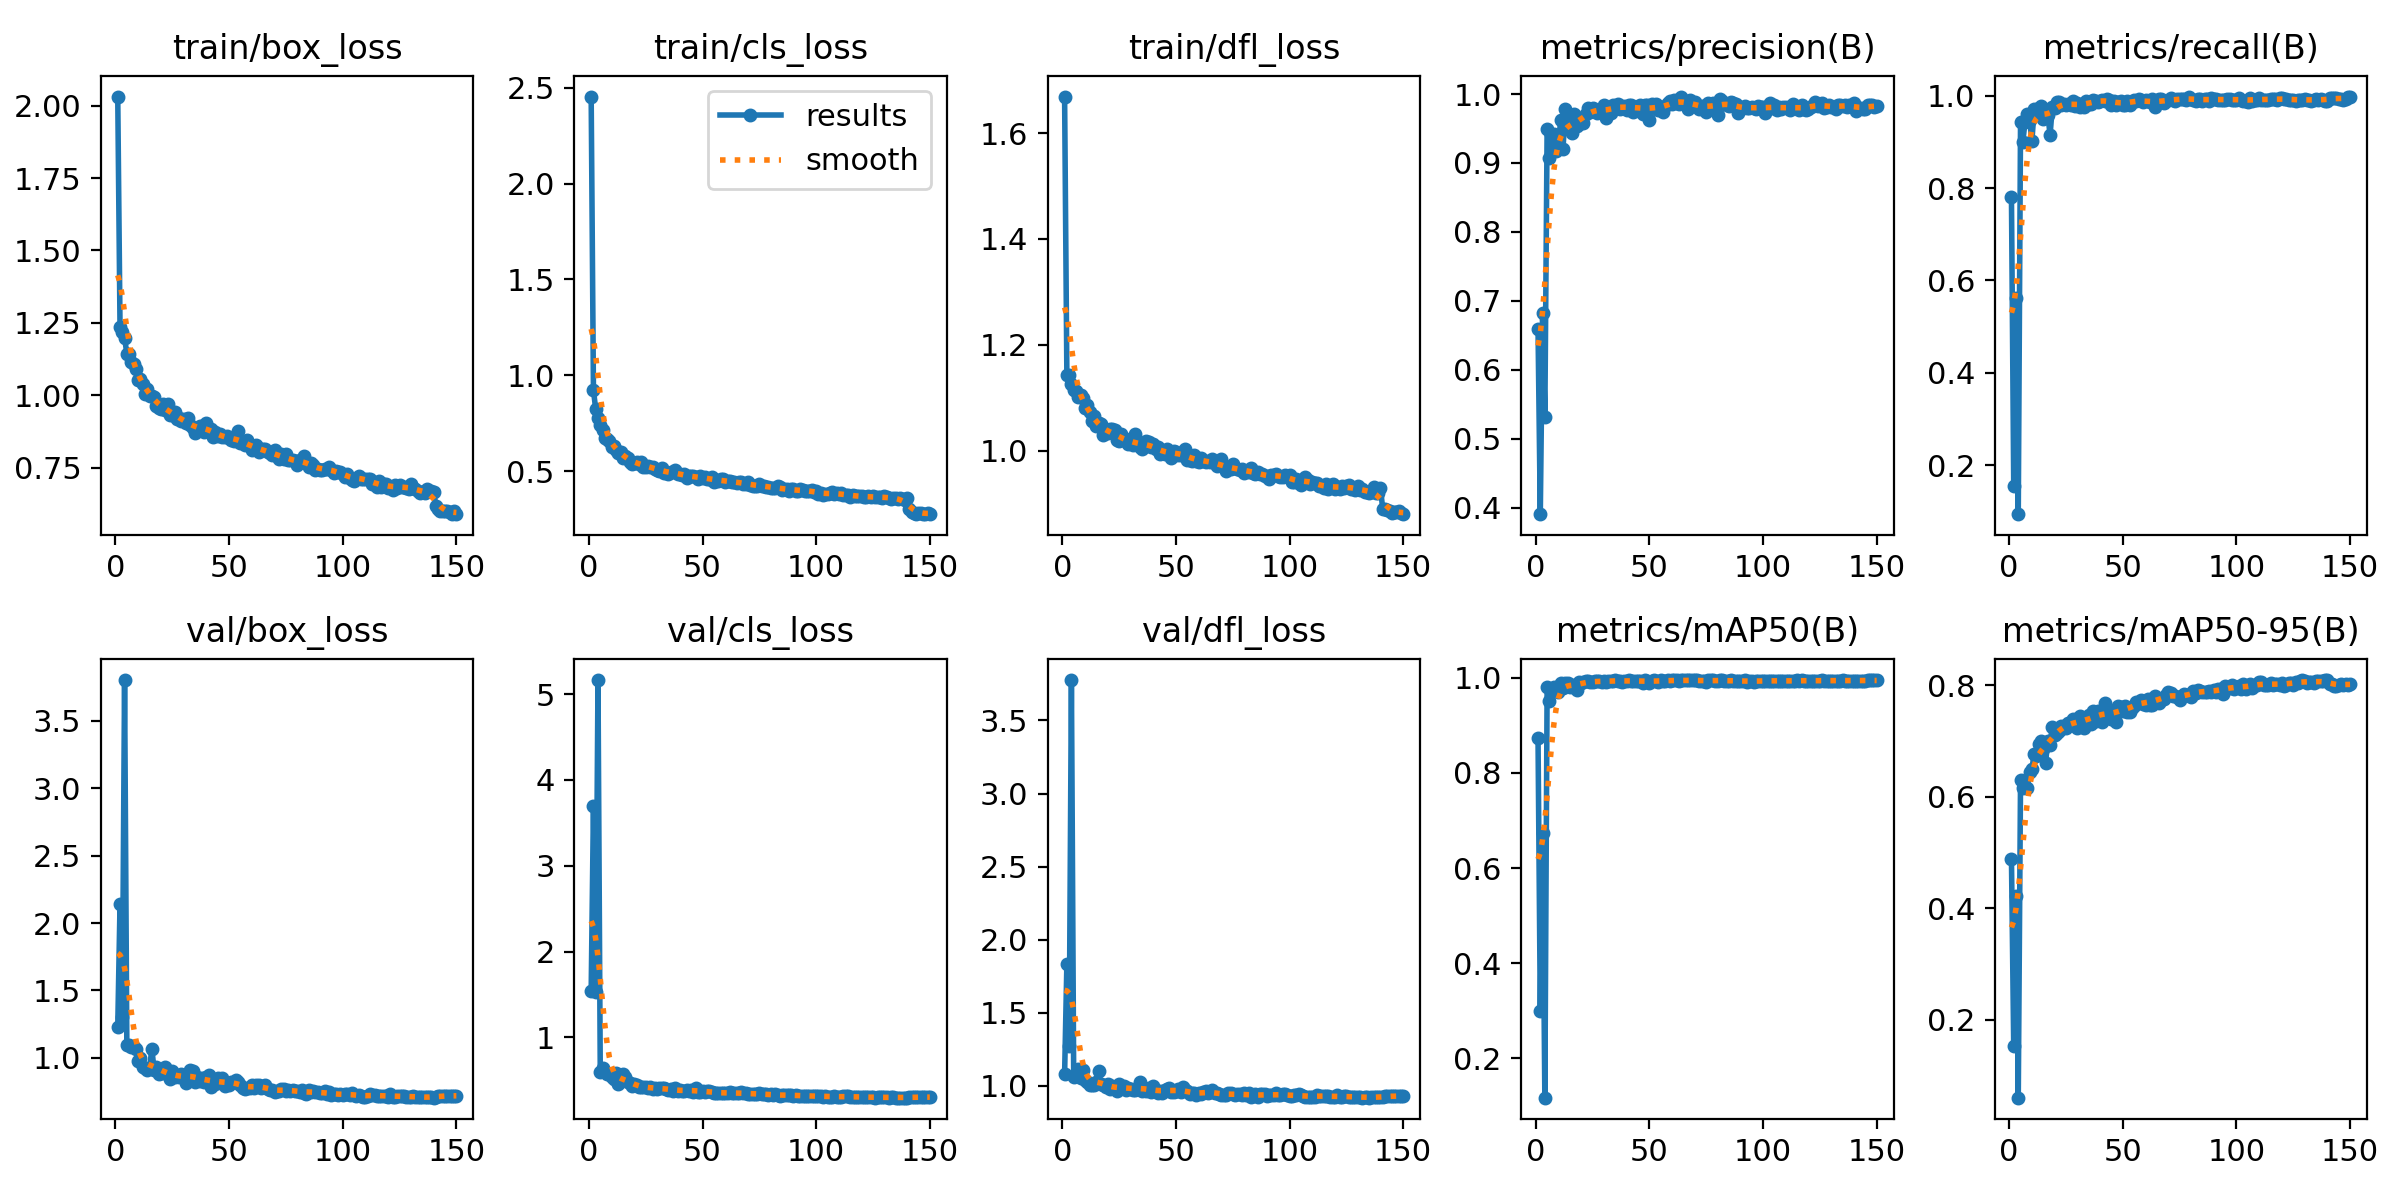

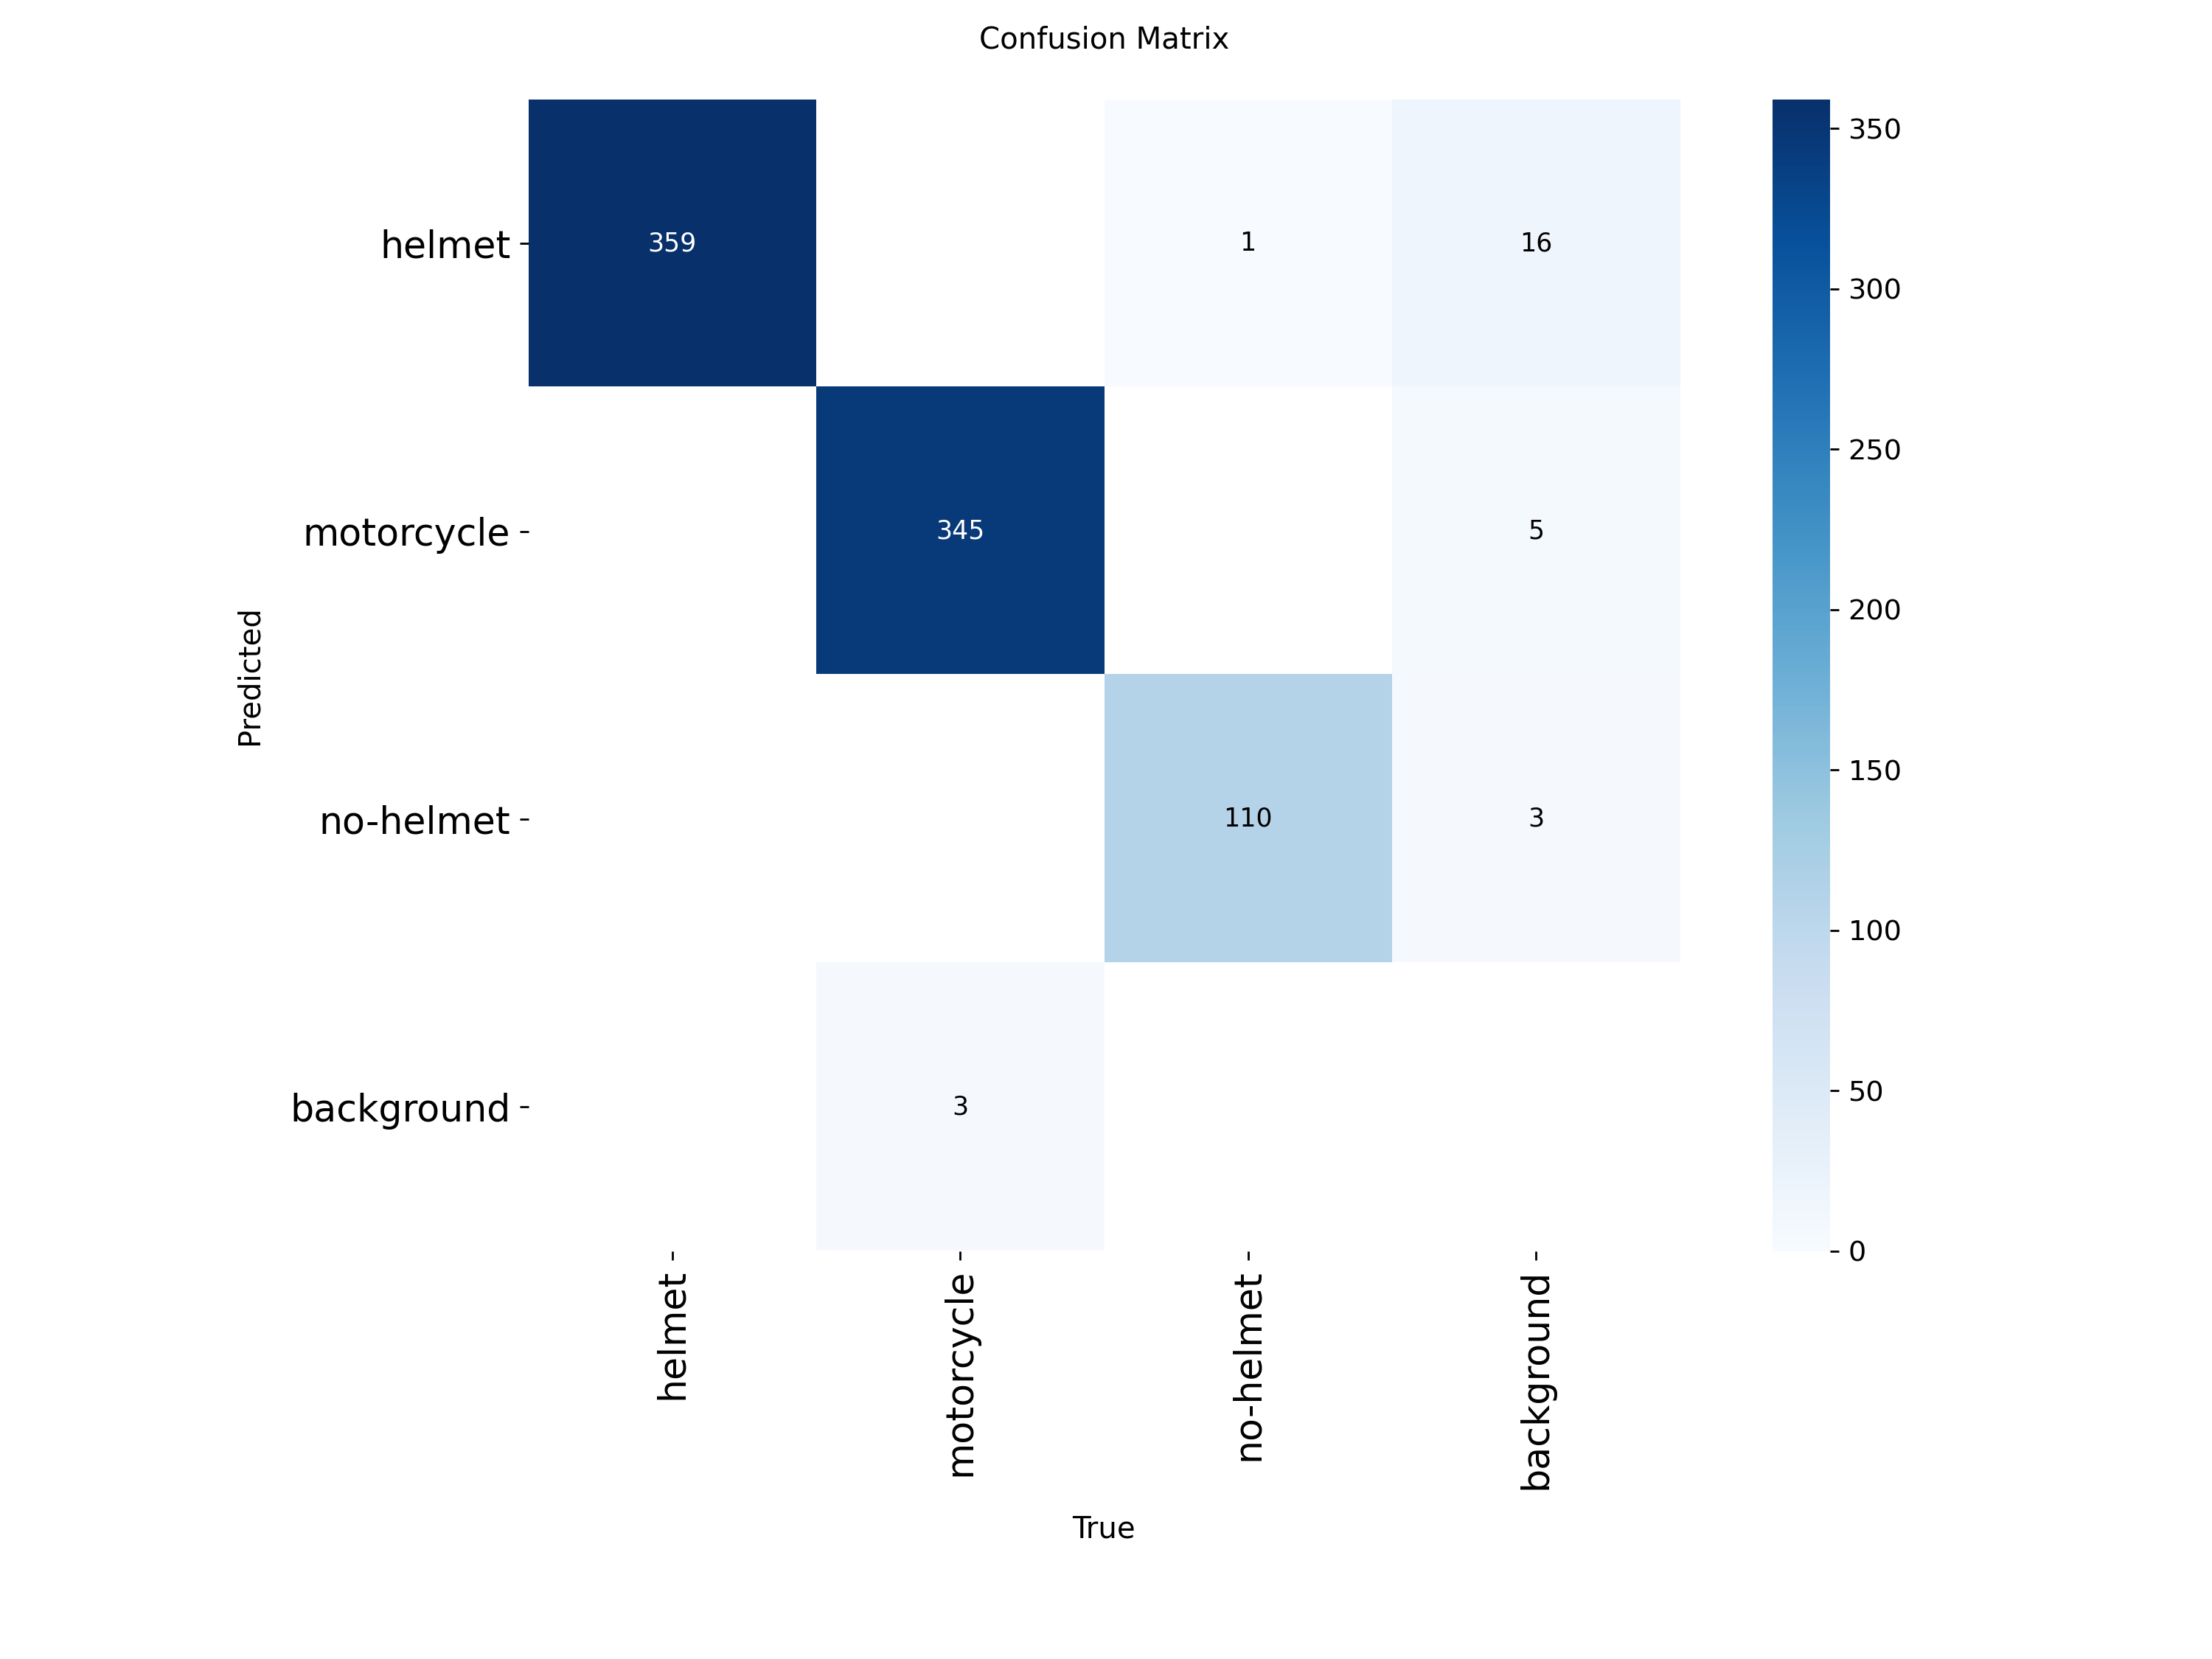



[!] Warning: PR_curve.png has not been generated yet.
[!] Warning: F1_curve.png has not been generated yet.


In [4]:
from IPython.display import Image, display, HTML
import os

# Define directories where YOLO saves the graphs
train_dir = "/kaggle/working/SentinelAI/helmet_model_pro"
eval_dir = "/kaggle/working/SentinelAI/evaluation_results"

# Dictionary of charts to display
charts = [
    {"file": "results.png", "path": train_dir, "title": "1. Training Loss & Convergence Curves", "desc": "Shows how the loss decreases over epochs. Look for validation loss divergence to spot overfitting."},
    {"file": "confusion_matrix.png", "path": eval_dir, "title": "2. Confusion Matrix", "desc": "Identifies False Positives and False Negatives. Shows if the model confuses 'helmet' with 'no-helmet'."},
    {"file": "PR_curve.png", "path": eval_dir, "title": "3. Precision-Recall Curve", "desc": "Measures the trade-off between precision and recall. A curve closer to the top-right corner is better."},
    {"file": "F1_curve.png", "path": eval_dir, "title": "4. F1-Score Curve", "desc": "Shows the optimal Confidence Threshold to balance False Positives and False Negatives."}
]

print("VISUAL ANALYTICS & DIAGNOSTICS")
print("-" * 50)

for chart in charts:
    chart_path = os.path.join(chart["path"], chart["file"])
    
    # Fallback to train directory if eval doesn't have it
    if not os.path.exists(chart_path) and chart["path"] == eval_dir:
        chart_path = os.path.join(train_dir, chart["file"])
        
    if os.path.exists(chart_path):
        display(HTML(f"<h3>{chart['title']}</h3><p><i>{chart['desc']}</i></p>"))
        display(Image(filename=chart_path, width=900))
        print("\n")
    else:
        print(f"[!] Warning: {chart['file']} has not been generated yet.")

## 3. Export Trained Weights
During training, YOLO automatically saves the best-performing weights (`best.pt`) based on validation metrics (mAP). This execution block compresses the weights directory into a single `.zip` archive, allowing seamless download for our local inference pipeline.

In [9]:
import shutil

shutil.make_archive(
    "/kaggle/working/SentinelAI_Weights", 
    'zip', 
    "/kaggle/working/SentinelAI/helmet_model_pro/weights"
)

'/kaggle/working/SentinelAI_Weights.zip'

## 4. Random Inference & Visual Verification
To qualitatively assess the model's performance on unseen data, we randomly sample an image from the `test` dataset. We then load the newly trained `best.pt` weights and run inference. The output image, complete with predicted bounding boxes, class labels, and confidence scores, is displayed below.

In [ ]:
import glob
import os
from IPython.display import Image, display
from ultralytics import YOLO

# 1. Automatically locate the most recently generated 'best.pt' weight file
print("[*] Searching for the optimal weight file (best.pt)...")
weight_files = glob.glob("/kaggle/working/**/best.pt", recursive=True)

if len(weight_files) == 0:
    print("[!] FATAL ERROR: NO 'best.pt' FILE FOUND!")
    print("[!] ROOT CAUSE: Cell 2 (Training phase) has not been executed, or the training process was interrupted.")
    print("[!] SOLUTION: Please scroll up to Cell 2, run the training block, and wait for it to reach 100% completion before executing this inference cell.")
else:
    # Retrieve the most recently created 'best.pt' file
    latest_weight = max(weight_files, key=os.path.getctime)
    print(f"[+] Optimal AI weights located at: {latest_weight}")

    # 2. Configure EXACT dataset path
    # Update the exact path (including the Roboflow sub-directory)
    base_path = "/kaggle/input/datasets/tranquangduyenk17ct/helmet-detection-1/helmet plate detection 4.v1i.yolov8" 
    
    target_image_name = "frame_10_579_jpg" 
    
    # [NEW FEATURE] Smart Search: Automatically handle missing extensions (.jpg) and hash codes
    search_pattern = os.path.join(base_path, "test", "images", f"*{target_image_name}*")
    matching_images = [f for f in glob.glob(search_pattern) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    # 3. Verify if the target image exists using the smart search results
    if len(matching_images) > 0:
        test_img = matching_images[0]  # Get the first matching result
        actual_image_name = os.path.basename(test_img)  # Get the exact full file name
        print(f"[*] Running inference on fixed Golden Sample: {actual_image_name}")

        # 4. Initialize the YOLO model
        best_model = YOLO(latest_weight)

        # 5. Execute object detection inference
        results = best_model.predict(
            source=test_img, 
            save=True, 
            project="/kaggle/working/SentinelAI", 
            name="test_inference", 
            exist_ok=True
        )

        # 6. Render the annotated output image in the notebook
        result_img_path = f"/kaggle/working/SentinelAI/test_inference/{actual_image_name}"
        
        print("\n[+] INFERENCE RESULT:")
        display(Image(filename=result_img_path, width=800))
        
    else:
        print(f"[!] ERROR: No image containing '{target_image_name}' was found.")
        print(f"[!] PATH CHECKED: {os.path.join(base_path, 'test', 'images')}")